In [71]:
import numpy as np
import tensorflow as tf 
import os
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

In [72]:
img_rows, img_cols = 102, 136
data_path = 'dataset'
x, y = [], []
counter = 0
classes = os.listdir(data_path)
print(classes)

['Boot', 'Sandal', 'Shoe']


In [73]:
ctr = 0
for class_name in os.listdir(data_path):
    class_dir = os.path.join(data_path, class_name)
    if not os.path.isdir(class_dir):
        continue
    for img_file in os.listdir(class_dir):
        # if ctr > 10000:
        #     break
        img_path = os.path.join(class_dir, img_file)
        label = counter
        image = tf.keras.preprocessing.image.load_img(img_path, target_size=(img_rows, img_cols))
        image = tf.keras.preprocessing.image.img_to_array(image)
        x.append(image)
        y.append(label)
        # ctr += 1
    counter += 1

x = np.array(x)
y = np.array(y)

x = x.astype('float32') / 255.0

X_train, X_temp, y_train, y_temp = train_test_split(x, y, test_size=0.2, random_state=42)
X_test, X_val, y_test, y_val = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

y_train = tf.keras.utils.to_categorical(y_train, num_classes=3)
y_test = tf.keras.utils.to_categorical(y_test, num_classes=3)
y_val = tf.keras.utils.to_categorical(y_val, num_classes=3)

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

X_train shape: (12000, 102, 136, 3)
y_train shape: (12000, 3)


In [74]:
model = tf.keras.Sequential()
model.add(tf.keras.layers.Conv2D(6, (5, 5), activation='relu', input_shape=(img_rows, img_cols, 3)))
model.add(tf.keras.layers.AveragePooling2D(pool_size=(2, 2), strides=2))
model.add(tf.keras.layers.Conv2D(16, (5, 5), activation='relu'))
model.add(tf.keras.layers.AveragePooling2D(pool_size=(2,2), strides=2))
model.add(tf.keras.layers.Flatten())
model.add(tf.keras.layers.Dense(120, activation='relu'))
model.add(tf.keras.layers.Dense(84, activation='relu'))
model.add(tf.keras.layers.Dense(3, activation='softmax'))
model.summary()

c:\Users\Pongo\Documents\LATIHAN-CODING\Python\DeepLearning\env-dl\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_14 (Conv2D)              │ (None, 98, 132, 6)     │           456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_14            │ (None, 49, 66, 6)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 45, 62, 16)     │         2,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_15            │ (None, 22, 31, 16)     │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_7 (Flatten)             │ (None, 10912)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 120)            │     1,309,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 84)             │        10,164 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 3)              │           255 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,322,851 (5.05 MB)

 Trainable params: 1,322,851 (5.05 MB)

 Non-trainable params: 0 (0.00 B)

In [75]:
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
hist = model.fit(X_train, y_train, batch_size=120, validation_data=(X_val, y_val))

100/100 ━━━━━━━━━━━━━━━━━━━━ 11s 87ms/step - accuracy: 0.7987 - loss: 0.4790 - val_accuracy: 0.9020 - val_loss: 0.2614


47/47 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step


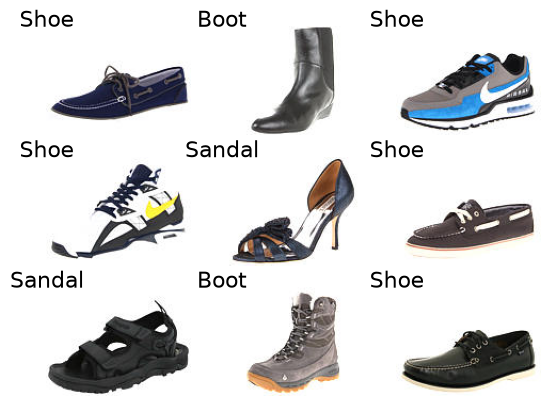

In [76]:
prediction = model.predict(X_test)

prediction_labels = np.argmax(prediction, axis=1)
for i in range(9):
    plt.subplot(3, 3, i+1)
    plt.imshow(X_test[i])
    plt.axis('off')
    plt.text(0.5, -0.15, classes[prediction_labels[i]], fontsize=16, ha='center')

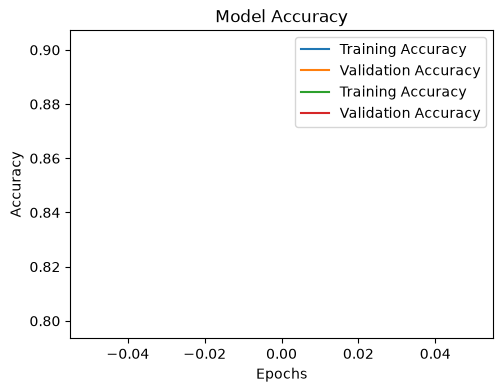

In [77]:
plt.figure(figsize=(12,4))

plt.subplot(1,2, 2)
plt.plot(hist.history['accuracy'], label='Training Accuracy')
plt.plot(hist.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Model Accuracy')
plt.legend()

plt.subplot(1,2, 2)
plt.plot(hist.history['accuracy'], label='Training Accuracy')
plt.plot(hist.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Model Accuracy')
plt.legend()

plt.show()